# Introduction

This notebook conducts the investigation of which projection algorithm and distance measure will be used for the final user interface.

## Preperation

We start off by: 
* loading the dataset that is subject for Dimensionality Reduction (DR),
* loading the yaml file classifying the attribute types in the dataset,
* installing the necessary depencencies in order to access DR libraries and distance metrics.

In [1]:
import numpy as np
import pandas as pd
from yaml import SafeLoader, load

from resources.paths import DATA_ROOT_PROCESSED


In [2]:
df = pd.read_csv(DATA_ROOT_PROCESSED / "student_dropout_dataset.csv")
with open(DATA_ROOT_PROCESSED / "attribute_types.yaml") as f:
    attribute_types = load(f, Loader=SafeLoader)


In [3]:
display(df)
display(attribute_types)

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Scholarship holder,Age at enrollment,International,Graduation status,Curricular units (credited),Curricular units (enrolled),Curricular units (evaluations),Curricular units (approved),Curricular units (grade),Curricular units (without evaluations)
0,1,17,5,171,1,1,122.0,1,19,12,...,0,20,0,0,0.0,0.0,0.0,0.0,0.000000,0.0
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,19,0,2,0.0,6.0,6.0,6.0,13.833333,0.0
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,19,0,0,0.0,6.0,0.0,0.0,0.000000,0.0
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,20,0,2,0.0,6.0,9.0,5.5,12.914286,0.0
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,45,0,2,0.0,6.0,7.5,5.5,12.666667,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,19,0,2,0.0,6.0,7.5,5.0,13.133333,0.0
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,18,1,0,0.0,6.0,6.0,4.0,11.500000,0.0
4421,1,1,1,9500,1,1,154.0,1,37,37,...,1,30,0,0,0.0,7.5,8.5,4.0,14.206250,0.0
4422,1,1,1,9147,1,1,180.0,1,37,37,...,1,20,0,2,0.0,5.0,5.5,5.0,12.900000,0.0


{'binary': ['Displaced',
  'Educational special needs',
  'Debtor',
  'Tuition fees up to date',
  'Gender',
  'Scholarship holder',
  'International'],
 'nominal': ['Marital Status',
  'Application mode',
  'Course',
  'Daytime/evening attendance',
  'Previous qualification',
  'Nationality',
  "Mother's qualification",
  "Father's qualification",
  "Mother's occupation",
  "Father's occupation",
  'Graduation status'],
 'numerical': ['Admission grade',
  'Age at enrollment',
  'Previous qualification (grade)',
  'Curricular units (credited)',
  'Curricular units (enrolled)',
  'Curricular units (evaluations)',
  'Curricular units (approved)',
  'Curricular units (grade)',
  'Curricular units (without evaluations)'],
 'ordinal': ['Application order']}

In [4]:
%pip install "scikit-learn>=1.9.1"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install "umap-learn>=0.6.0"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
%pip install "gower>=0.1.2"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Chosen projection algorithms and distance metrics

Considering that the analytical goals of the interface are to enable users to discover potential student profiles and identify outliers in terms of academic performance, t-SNE, UMAP, and MDS are considered as dimensionality reduction techniques.

t-SNE and UMAP primarily preserve local neighbourhood structures, making them suitable for identifying groups of students with similar characteristics and discovering potential student profiles. However, these methods do not reliably preserve global distances, meaning that the relative distances between clusters in the resulting latent space have no well-defined interpretation. This limits their suitability for identifying outliers, where the relative distances between observations are important for assessing how substantially an individual student differs from the rest of the population.

MDS is therefore also considered, as it aims to preserve pairwise distances between observations during dimensionality reduction. This makes it potentially more suitable for exploring the global structure of the student population and identifying observations that are substantially different from others.

Alongside these techniques, we consider four distance metrics, which are applied consistently across all methods: Euclidean, Manhattan, Gower, and the Heterogeneous Euclidean-Overlap Metric (HEOM). This selection provides a range of distance measures with different approaches to handling mixed data types. The two latter metrics support both numerical and categorical attributes, whereas Euclidean and Manhattan distances are applied only to numerical and ordinal features. Including categorical attributes in the latter two would require one-hot encoding, which would substantially increase the dimensionality of the feature space.

### Preparing distance metrics

Prepare the distance matrices for each of the selected distance metrics, which will serve as input to the dimensionality reduction (DR) methods. Note that numerical features are standardized using StandardScaler to ensure comparable attribute value ranges.

In [7]:
from gower import gower_matrix
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler

In [8]:
from scipy.spatial.distance import cdist


def HEOM(df: pd.DataFrame, cat_features: np.array[bool]):
    num_mask = ~cat_features

    n = len(df)
    dist_matrix = np.zeros((n, n), dtype=float)

    # Numerical attributes
    if num_mask.any():
        X_num = df.loc[:, num_mask].to_numpy(dtype=float)

        ranges = np.ptp(X_num, axis=0)
        ranges[ranges == 0] = 1.0

        # subtracting min value in nominator is not needed as it will be canceled
        # when computing pairwise differences
        X_num = X_num / ranges

        dist_matrix += cdist(
            X_num, X_num, metric="sqeuclidean"
        )

    # Categorical attributes
    if cat_features.any():
        X_cat = df.loc[:, cat_features].to_numpy()

        for k in range(X_cat.shape[1]):
            dist_matrix += (
                X_cat[:, k, None] != X_cat[None, :, k]
            )

    return np.sqrt(dist_matrix)


In [9]:
target_column = "Graduation status"

# We put categorical columns in a list such that gower and HEOM knows which columns are categorical
# We exclude the target column from the categorical columns list as this column is the target variable subject for analysis
# The remaining columns are considered numerical by the gower and HEOM function
categorical_columns = [col for col in attribute_types["binary"] + attribute_types["nominal"] if col != target_column]

numerical_columns = attribute_types["numerical"] + attribute_types["ordinal"]

print("Categorical columns:")
display(categorical_columns)
print("Numerical columns:")
display(numerical_columns)

Categorical columns:


['Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'International',
 'Marital Status',
 'Application mode',
 'Course',
 'Daytime/evening attendance',
 'Previous qualification',
 'Nationality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation"]

Numerical columns:


['Admission grade',
 'Age at enrollment',
 'Previous qualification (grade)',
 'Curricular units (credited)',
 'Curricular units (enrolled)',
 'Curricular units (evaluations)',
 'Curricular units (approved)',
 'Curricular units (grade)',
 'Curricular units (without evaluations)',
 'Application order']

In [10]:
# Computing the distance matrices
cat_features = df.columns.isin(categorical_columns)
gow_mat = gower_matrix(df, cat_features=cat_features)
heom_mat = HEOM(df, cat_features=cat_features)

df_numerical_scaled = StandardScaler().fit_transform(df[numerical_columns])

euc_mat = pairwise_distances(df_numerical_scaled, metric="euclidean")
man_mat = pairwise_distances(df_numerical_scaled, metric="manhattan")

### Experimentation

We then configure and execute each dimensionality reduction (DR) method using the selected distance metrics.

In [11]:
from sklearn.manifold import MDS, TSNE
from umap import UMAP

/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
n_components = 2
random_state = 42
results = {
    "gower": {
        "mds": None,
        "tsne": None,
        "umap": None
    },
    "heom": {
        "mds": None,
        "tsne": None,
        "umap": None
    },
    "euclidean": {
        "mds": None,
        "tsne": None,
        "umap": None
    },
    "manhattan": {
        "mds": None,
        "tsne": None,
        "umap": None
    }
}

In [20]:

mds_precomp = MDS(
    n_components=n_components,
    metric="precomputed",
    metric_mds=True,
    n_init=1,
    max_iter=100,
    eps=1e-3,
    normalized_stress=True,
    random_state=random_state,
    n_jobs=-1
)

tsne_precomp = TSNE(
    n_components=n_components,
    metric="precomputed",
    perplexity=30,
    early_exaggeration=12,
    learning_rate="auto",
    max_iter=1000,
    init="random",
    method="barnes_hut",
    angle=0.5,
    random_state=random_state
)

umap_precomp = UMAP(
    n_components=n_components,
    metric="precomputed",
    n_neighbors=15,
    min_dist=0.1,
    spread=1.0,
    n_epochs=500,
    learning_rate=1.0,
    init="spectral",
    random_state=random_state,
    n_jobs=-1
)


In [22]:
# MDS
mds_gower_latent = mds_precomp.fit_transform(gow_mat)
print("Gower done")
mds_heom_latent = mds_precomp.fit_transform(heom_mat)
print("HEOM done")
mds_euclidean_latent = mds_precomp.fit_transform(euc_mat)
print("Euclidean done")
mds_manhattan_latent = mds_precomp.fit_transform(man_mat)
print("Manhattan done")

results["gower"]["mds"] = mds_gower_latent
results["heom"]["mds"] = mds_heom_latent
results["euclidean"]["mds"] = mds_euclidean_latent
results["manhattan"]["mds"] = mds_manhattan_latent

/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


Gower done


/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


HEOM done


/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


Euclidean done


/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


Manhattan done


In [15]:
# TSNE
tsne_gower_latent = tsne_precomp.fit_transform(gow_mat)
tsne_heom_latent = tsne_precomp.fit_transform(heom_mat)
tsne_euclidean_latent = tsne_precomp.fit_transform(euc_mat)
tsne_manhattan_latent = tsne_precomp.fit_transform(man_mat)

results["gower"]["tsne"] = tsne_gower_latent
results["heom"]["tsne"] = tsne_heom_latent
results["euclidean"]["tsne"] = tsne_euclidean_latent
results["manhattan"]["tsne"] = tsne_manhattan_latent

In [16]:
# UMAP
umap_gower_latent = umap_precomp.fit_transform(gow_mat)
umap_heom_latent = umap_precomp.fit_transform(heom_mat)
umap_euclidean_latent = umap_precomp.fit_transform(euc_mat)
umap_manhattan_latent = umap_precomp.fit_transform(man_mat)

results["gower"]["umap"] = umap_gower_latent
results["heom"]["umap"] = umap_heom_latent
results["euclidean"]["umap"] = umap_euclidean_latent
results["manhattan"]["umap"] = umap_manhattan_latent

/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/umap/umap_.py:3002: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt9

## Comparative evaluation

In [24]:
import matplotlib.pyplot as plt

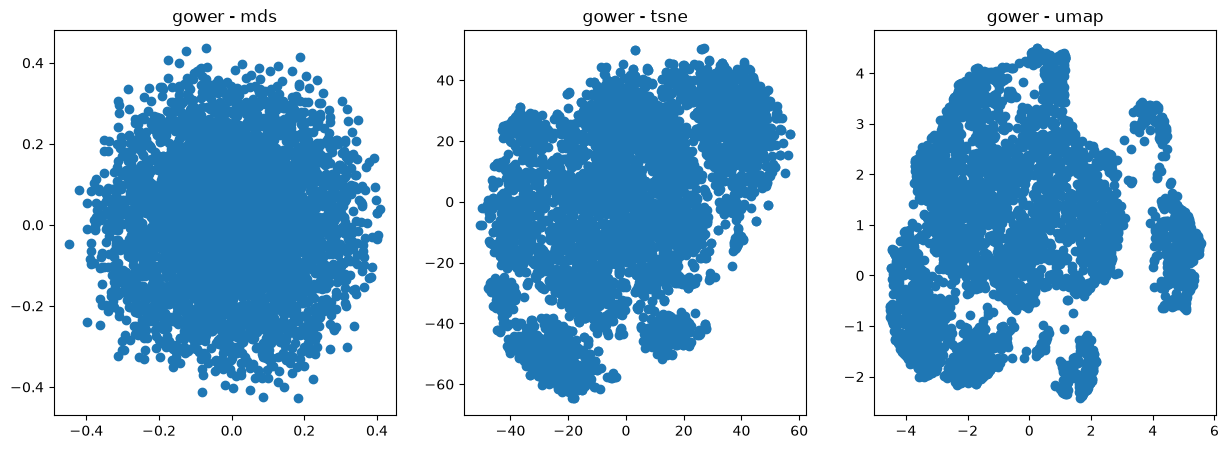

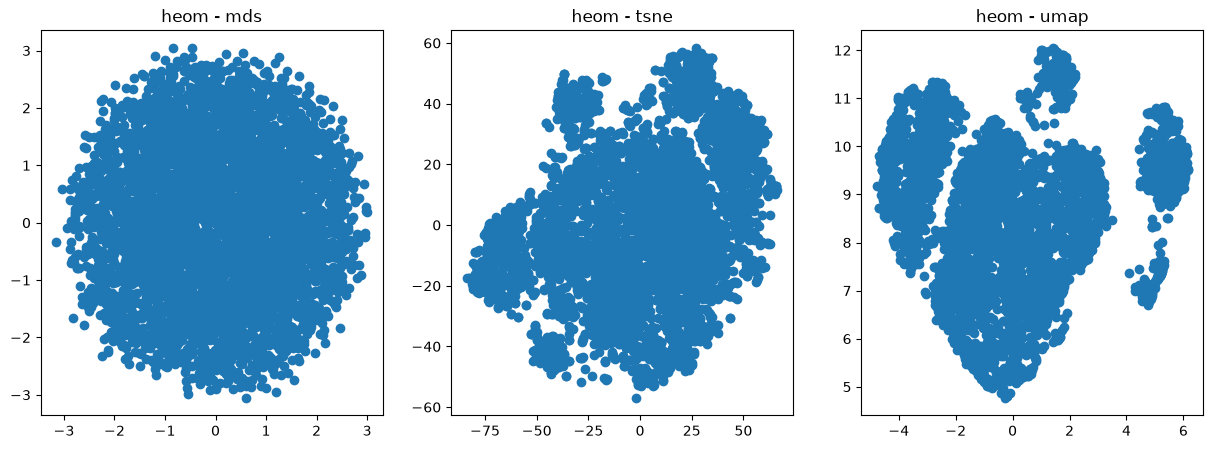

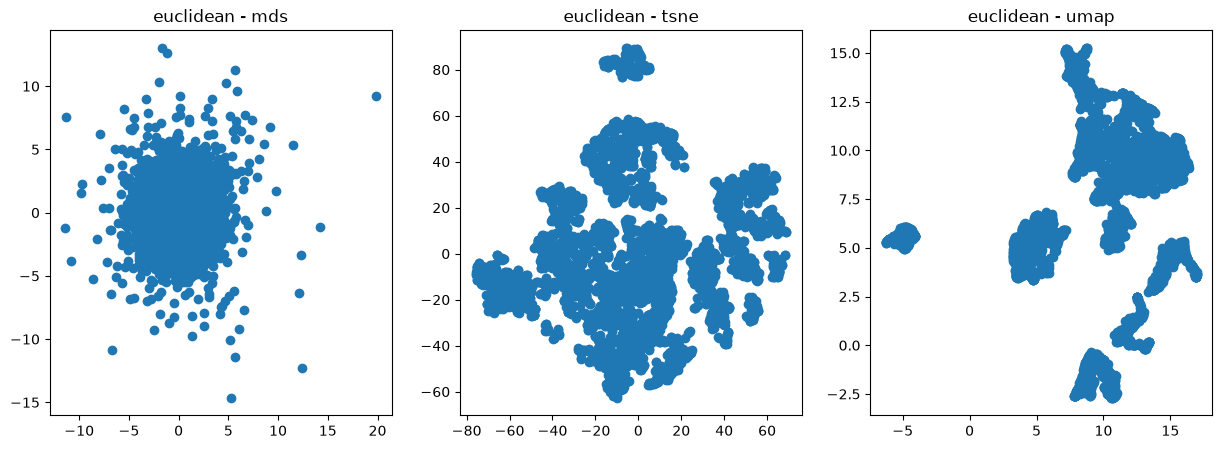

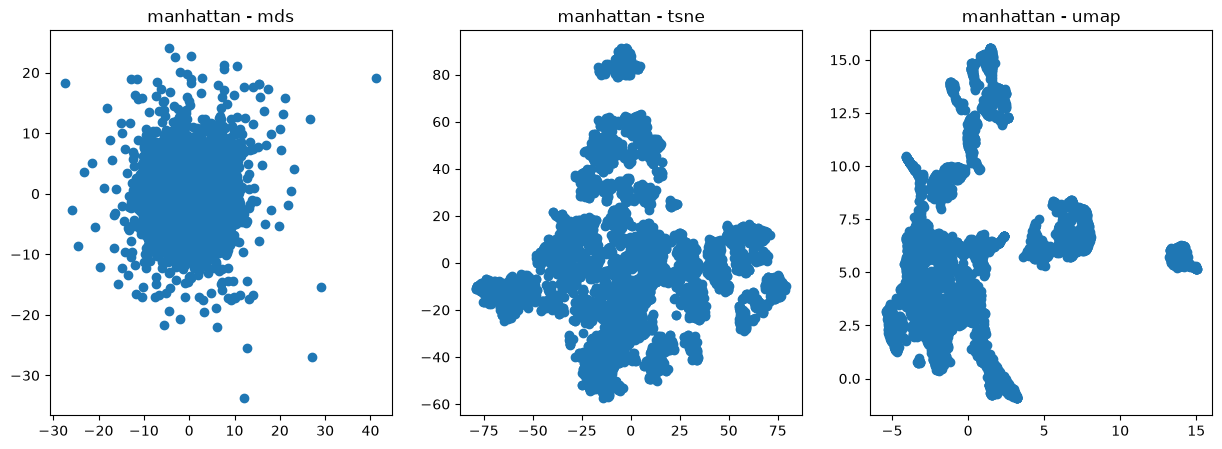

In [27]:

# For each metric in results, visualize the projections for each method in three different figures in one row
# include labeling the points based on 'Graduation status' feature in df
for metric, projections in results.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for i, (method, latent) in enumerate(projections.items()):
        axes[i].scatter(latent[:, 0], latent[:, 1])
        axes[i].set_title(f"{metric} - {method}")
    plt.show()

## Technique selection